# Option 2: demonstrations - behaviour cloning - PPO

## 1. Setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os, shutil, subprocess, json, glob, re, time
DRIVE_ROOT = "/content/drive/MyDrive/spirob_vision"
OUT   = f"{DRIVE_ROOT}/polar_teacher"          # Phase 3 checkpoints (stageA, stageA15 ...)
DEMO  = f"{DRIVE_ROOT}/polar_demos"
os.makedirs(DEMO, exist_ok=True)
WS    = f"{DRIVE_ROOT}/workspace_map"
SIR_CKPT = f"{DRIVE_ROOT}/sir_stage1/model_499.pt"
REPO  = "/content/spirob-polar"
BRANCH = "origin/research/s2-spawn-randomization"
LOGS  = f"{REPO}/logs/rsl_rl/spirob_minimal"
NUM_ENVS = 256            # T4; on a G4 you can use 512
os.makedirs(OUT, exist_ok=True)
if shutil.which("uv") is None:
    subprocess.run("curl -LsSf https://astral.sh/uv/install.sh | sh", shell=True, check=True)
    os.environ["PATH"] = f"/root/.local/bin:{os.environ['PATH']}"
if not os.path.isdir(REPO):
    subprocess.run(["git", "clone", "https://github.com/YADlin/spirob-mjlab", REPO], check=True)
os.chdir(REPO)
subprocess.run(["git", "fetch", "origin"], check=True)
subprocess.run(["git", "checkout", "-B", "polar-work", BRANCH], check=True)
subprocess.run(["uv", "sync"], check=True)
print(subprocess.run(["uv", "run", "python", "-c", "import torch; print('GPU:', torch.cuda.get_device_name(0))"],
                     capture_output=True, text=True).stdout)
print("sir checkpoint:", os.path.isfile(SIR_CKPT), os.path.getsize(SIR_CKPT) if os.path.isfile(SIR_CKPT) else "")
print("stages already on Drive:", sorted(os.listdir(OUT)))

## 2. Write the scripts

In [ ]:
%%writefile /content/spirob-polar/tools/polar_tasks.py

from mjlab.managers.event_manager import EventTermCfg
from mjlab.managers.metrics_manager import MetricsTermCfg
from mjlab.tasks.registry import register_mjlab_task

import spirob_mjlab  # noqa: F401  (registers  tasks)
from spirob_mjlab import mdp
from spirob_mjlab.entities import movable_pedestal_cfg
from spirob_mjlab.env_cfgs import spirob_egg_to_bucket_stage1_env_cfg
from spirob_mjlab.rl_cfg import Stage2FineTuneRunner, spirob_ppo_runner_cfg

RADIUS_M = (0.120, 0.200)
POLAR_TASKS = {
    "Mjlab-SpiRob-Polar-Right": (RADIUS_M, (30.0, 80.0)),
    "Mjlab-SpiRob-Polar-Left": (RADIUS_M, (100.0, 150.0)),
    "Mjlab-SpiRob-Polar-Wide": (RADIUS_M, (30.0, 150.0)),
}


def polar_env_cfg(radius_range_m, angle_range_deg, play=False):
    cfg = spirob_egg_to_bucket_stage1_env_cfg(play=play)
    if play:
        cfg.episode_length_s = 8.0
    cfg.scene.entities["pedestal"] = movable_pedestal_cfg()
    cfg.events["stage2_egg_pedestal_spawn"] = EventTermCfg(
        func=mdp.reset_stage2_sector_egg_and_pedestal,
        mode="reset",
        params={
            "radius_range_m": radius_range_m,
            "angle_range_deg": angle_range_deg,
            # 1 x 1 strata: a wide sector crosses the robot/bucket exclusion zones,
            # and fully-excluded strata would make stratified sampling fail
            "radial_strata": 1,
            "angular_strata": 1,
            "schedule_length": 10,
            "nominal_slots": 1,
            "retention_slots": 3,
            "max_resample_attempts": 256,
            "min_robot_centerline_clearance": 0.038,
            "min_bucket_center_clearance": 0.055,
        },
    )
    cfg.metrics = {
        "spawn_radius_mm": MetricsTermCfg(func=mdp.stage2_spawn_radius_mm, reduce="last"),
        "spawn_angle_deg": MetricsTermCfg(func=mdp.stage2_spawn_angle_deg, reduce="last"),
        "spawn_is_sector": MetricsTermCfg(func=mdp.stage2_spawn_is_sector, reduce="last"),
        "spawn_rejection_count": MetricsTermCfg(func=mdp.stage2_spawn_rejection_count, reduce="last"),
    }
    return cfg


for _task_id, (_r, _th) in POLAR_TASKS.items():
    register_mjlab_task(
        task_id=_task_id,
        env_cfg=polar_env_cfg(_r, _th, play=False),
        play_env_cfg=polar_env_cfg(_r, _th, play=True),
        rl_cfg=spirob_ppo_runner_cfg(stage2=True),
        runner_cls=Stage2FineTuneRunner,
    )


register_mjlab_task(
    task_id="Mjlab-SpiRob-Polar-Arc15",
    env_cfg=polar_env_cfg((0.139, 0.179), (50.8, 75.8), play=False),
    play_env_cfg=polar_env_cfg((0.139, 0.179), (50.8, 75.8), play=True),
    rl_cfg=spirob_ppo_runner_cfg(stage2=True),
    runner_cls=Stage2FineTuneRunner,
)
POLAR_TASKS["Mjlab-SpiRob-Polar-Arc15"] = ((0.139, 0.179), (50.8, 75.8))

In [ ]:
%%writefile /content/spirob-polar/tools/polar_check.py

import sys, os, json, time, argparse, math
from dataclasses import asdict
sys.path.insert(0, "/content/spirob-polar/tools")
import numpy as np
import torch
from tensordict import TensorDict
import polar_tasks  # noqa: F401  (registers the polar tasks)
from mjlab.envs import ManagerBasedRlEnv
from mjlab.rl import MjlabOnPolicyRunner, RslRlVecEnvWrapper
from mjlab.tasks.registry import load_env_cfg, load_rl_cfg, load_runner_cls

ap = argparse.ArgumentParser()
ap.add_argument("--mode", choices=["spawns", "eval"], required=True)
ap.add_argument("--task", default="Mjlab-SpiRob-Polar-Wide")
ap.add_argument("--out", required=True)
ap.add_argument("--ws", default="", help="workspace_map folder, for the background map")
ap.add_argument("--num_envs", type=int, default=512)
ap.add_argument("--rounds", type=int, default=3)
ap.add_argument("--checkpoint", default="")
ap.add_argument("--label", default="policy")
a = ap.parse_args()
os.makedirs(a.out, exist_ok=True)
DEV = "cuda:0"
BUCKET = (-0.05, 0.15)
GROUP = {0: "nominal", 1: "retention", 2: "sector"}


def make_env():
    cfg = load_env_cfg(a.task, play=False)
    cfg.scene.num_envs = a.num_envs
    cfg.auto_reset = False
    cfg.seed = 1001
    cfg.observations["actor"].enable_corruption = False
    cfg.observations["critic"].enable_corruption = False
    env = ManagerBasedRlEnv(cfg=cfg, device=DEV)
    vec = RslRlVecEnvWrapper(env, clip_actions=load_rl_cfg(a.task).clip_actions)
    return env, vec


def spawn_info(env):
    egg = env.scene["egg"].data.root_link_pos_w - env.scene.env_origins
    grp = getattr(env, "_stage2_spawn_group", torch.full((env.num_envs,), -1, device=DEV))
    return egg[:, :2].clone(), egg[:, 2].clone(), grp.clone()


def flags(env):
    tm = env.termination_manager
    g = lambda n: tm.get_term(n).bool()
    return g("success_egg_inside_bucket"), g("egg_fell") | g("egg_oob"), g("nan_state")


def run_round(env, vec, policy, steps):
    """One synchronous batch: every env runs one episode; finished envs are reset and masked."""
    vec.reset()
    xy, z0, grp = spawn_info(env)
    # same method as sir's evaluators: build the first observation after the reset
    obs = TensorDict(env.observation_manager.compute(update_history=True), batch_size=[env.num_envs])
    N = env.num_envs
    done = torch.zeros(N, dtype=torch.bool, device=DEV)
    succ, fell, crash = done.clone(), done.clone(), done.clone()
    min_z = z0.clone()
    for t in range(steps):
        with torch.no_grad():
            act = policy(obs) if policy is not None else torch.zeros((N, 2), device=DEV)
        obs, _, dones, _ = vec.step(act)
        ez = env.scene["egg"].data.root_link_pos_w[:, 2]
        min_z = torch.where(done, min_z, torch.minimum(min_z, ez))
        s, f, n = flags(env)
        new = ~done & (s | f | n)
        succ |= new & s; fell |= new & f & ~s; crash |= new & n & ~s
        done |= new
        if bool(done.all()):
            break
        ended = torch.nonzero(dones.bool()).flatten()
        if len(ended):
            env.reset(env_ids=ended)
    return dict(xy=xy.cpu().numpy(), z0=z0.cpu().numpy(), group=grp.cpu().numpy(),
                success=succ.cpu().numpy(), fell=fell.cpu().numpy(), crash=crash.cpu().numpy(),
                drop_mm=((z0 - min_z) * 1000).cpu().numpy())


def background(ax):
    import matplotlib.pyplot as plt
    LIM, CELL = 0.35, 0.005
    NC = int(round(2 * LIM / CELL))
    grid = np.zeros(NC * NC)
    for f in ("hold.npz", "random.npz"):
        p = os.path.join(a.ws, f)
        if a.ws and os.path.isfile(p):
            grid += np.load(p)["body"]
    if grid.any():
        ax.imshow(np.log1p(grid.reshape(NC, NC)), origin="lower", extent=[-LIM, LIM, -LIM, LIM],
                  cmap="Greys", alpha=0.6)
    for rr in (0.12, 0.20):
        ax.add_patch(plt.Circle((0, 0), rr, fill=False, ls="--", lw=0.8, color="tab:blue"))
    ax.add_patch(plt.Circle(BUCKET, 0.055, fill=False, lw=1, color="red"))
    ax.axvspan(-0.038, 0.038, color="orange", alpha=0.12)
    ax.plot(*BUCKET, "s", color="red", label="bucket (+55 mm exclusion)")
    ax.plot(0, 0, "k+", ms=10, label="robot base")
    ax.set_xlim(-0.25, 0.25); ax.set_ylim(-0.02, 0.26); ax.set_aspect("equal")
    ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")


def polar(xy):
    return np.hypot(xy[:, 0], xy[:, 1]) * 1000, np.degrees(np.arctan2(xy[:, 1], xy[:, 0]))


import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

if a.mode == "spawns":
    env, vec = make_env()
    rows = [run_round(env, vec, None, 150) for _ in range(a.rounds)]   # robot held still, 1.5 s
    R = {k: np.concatenate([r[k] for r in rows]) for k in rows[0]}
    r_mm, th = polar(R["xy"])
    stable = (~R["fell"]) & (~R["crash"]) & (R["drop_mm"] < 5)
    print(f"{a.task}: {len(r_mm)} spawns")
    for g, name in GROUP.items():
        m = R["group"] == g
        if m.any():
            print(f"  {name:9s}: {m.sum():5d} spawns | r {r_mm[m].min():5.0f}-{r_mm[m].max():5.0f} mm | "
                  f"theta {th[m].min():5.1f}-{th[m].max():5.1f} deg | egg stays on pedestal {stable[m].mean():.0%}")
    bd = np.hypot(R["xy"][:, 0] - BUCKET[0], R["xy"][:, 1] - BUCKET[1]) * 1000
    print(f"  closest spawn to bucket centre: {bd.min():.0f} mm (must be >= 55) | "
          f"closest to robot centreline: {np.abs(R['xy'][:, 0]).min() * 1000:.0f} mm (must be >= 38)")
    print(f"  ALL spawns stable: {bool(stable.all())}  ({(~stable).sum()} unstable)")
    fig, ax = plt.subplots(figsize=(8, 5))
    background(ax)
    ax.scatter(R["xy"][stable, 0], R["xy"][stable, 1], s=4, c="tab:green", label="spawn, egg stays")
    if (~stable).any():
        ax.scatter(R["xy"][~stable, 0], R["xy"][~stable, 1], s=12, c="tab:red", marker="x", label="egg fell / crash")
    ax.set_title(f"{a.task}: spawns over the workspace map"); ax.legend(fontsize=7, loc="upper left")
    plt.tight_layout(); f = f"{a.out}/spawns_{a.task.split('-')[-1]}.png"; plt.savefig(f, dpi=130)
    print("saved", f)

else:  # eval
    assert a.checkpoint and os.path.isfile(a.checkpoint), "give --checkpoint"
    env, vec = make_env()
    agent_cfg = load_rl_cfg(a.task)
    runner_cls = load_runner_cls(a.task) or MjlabOnPolicyRunner
    runner = runner_cls(vec, asdict(agent_cfg), device=DEV)
    runner.load(a.checkpoint, load_cfg={"actor": True}, strict=True, map_location=DEV)
    policy = runner.get_inference_policy(device=DEV)
    T = int(env.max_episode_length) + 1
    rows = []
    for i in range(a.rounds):
        t0 = time.time()
        rows.append(run_round(env, vec, policy, T))
        print(f"round {i + 1}/{a.rounds}: {time.time() - t0:.0f}s, success {rows[-1]['success'].mean():.0%}", flush=True)
    R = {k: np.concatenate([r[k] for r in rows]) for k in rows[0]}
    r_mm, th = polar(R["xy"])
    out = {"task": a.task, "checkpoint": a.checkpoint, "label": a.label, "groups": {}, "by_angle": []}
    print(f"\n{a.label} on {a.task}")
    for g, name in GROUP.items():
        m = R["group"] == g
        if m.any():
            out["groups"][name] = {"n": int(m.sum()), "success": float(R["success"][m].mean()),
                                   "fell": float(R["fell"][m].mean())}
            print(f"  {name:9s}: success {R['success'][m].mean():5.0%}  fell {R['fell'][m].mean():5.0%}  (n={m.sum()})")
    sec = R["group"] == 2
    print("\n  sector spawns by angle:\n  theta (deg) |   n  | success | fell")
    for lo in range(30, 150, 10):
        m = sec & (th >= lo) & (th < lo + 10)
        if m.any():
            out["by_angle"].append({"theta": lo, "n": int(m.sum()), "success": float(R["success"][m].mean()),
                                    "fell": float(R["fell"][m].mean())})
            print(f"   {lo:3d}-{lo + 10:3d}   | {m.sum():4d} | {R['success'][m].mean():6.0%}  | {R['fell'][m].mean():4.0%}")
    json.dump(out, open(f"{a.out}/eval_{a.label}_{a.task.split('-')[-1]}.json", "w"), indent=1)
    np.savez(f"{a.out}/eval_{a.label}_{a.task.split('-')[-1]}.npz", **R)
    fig, ax = plt.subplots(figsize=(8, 5))
    background(ax)
    col = np.where(R["success"], "tab:green", np.where(R["fell"], "tab:red", "tab:gray"))
    ax.scatter(R["xy"][:, 0], R["xy"][:, 1], s=5, c=col)
    ax.set_title(f"{a.label} on {a.task}: green = success, red = fell, grey = timeout")
    plt.tight_layout(); f = f"{a.out}/eval_{a.label}_{a.task.split('-')[-1]}.png"; plt.savefig(f, dpi=130)
    print("saved", f)

In [ ]:
%%writefile /content/spirob-polar/tools/train_polar.py

import os
import sys
from importlib.metadata import entry_points

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import polar_tasks  # noqa: F401,E402

eps = [e for e in entry_points(group="console_scripts") if e.name == "train"]
if not eps:
    sys.exit("could not find mjlab's `train` entry point")
sys.argv[0] = "train"
eps[0].load()()

In [ ]:
%%writefile /content/spirob-polar/tools/demo_pipeline.py

import sys, os, json, time, argparse, math
from dataclasses import asdict
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import numpy as np
import torch
from tensordict import TensorDict
import polar_tasks  # noqa: F401  (registers the polar tasks)
from mjlab.envs import ManagerBasedRlEnv
from mjlab.rl import MjlabOnPolicyRunner, RslRlVecEnvWrapper
from mjlab.tasks.registry import load_env_cfg, load_rl_cfg, load_runner_cls

ap = argparse.ArgumentParser()
ap.add_argument("--mode", choices=["search", "collect", "bc"], required=True)
ap.add_argument("--out", required=True, help="output folder (Drive)")
ap.add_argument("--task", default="Mjlab-SpiRob-Polar-Wide", help="env used for search / search demos")
ap.add_argument("--num_envs", type=int, default=1024)
ap.add_argument("--angles", default="40,45,50,55,60,65,70,75,80")
ap.add_argument("--radii", default="135,155,175")
ap.add_argument("--iters", type=int, default=10)
ap.add_argument("--segments", type=int, default=10)
ap.add_argument("--seg_len", type=int, default=50)
ap.add_argument("--horizon", type=int, default=600)
ap.add_argument("--sigma", type=float, default=0.4)
ap.add_argument("--init_motion", default="", help="json with a 'motion' (e.g. the 97% nominal motion)")
ap.add_argument("--table", default="demo_table.json")
ap.add_argument("--source", choices=["search", "policy"], default="search")
ap.add_argument("--min_success", type=float, default=0.3)
ap.add_argument("--rounds", type=int, default=3)
ap.add_argument("--jitter_mm", type=float, default=1.5)
ap.add_argument("--checkpoint", default="")
ap.add_argument("--policy_task", default="Mjlab-SpiRob-EggToBucket-Stage2Sector-Arc1")
ap.add_argument("--demos", default="", help="bc: comma-separated npz files")
ap.add_argument("--bc_steps", type=int, default=3000)
ap.add_argument("--bc_lr", type=float, default=3e-4)
ap.add_argument("--bc_batch", type=int, default=4096)
ap.add_argument("--save_ckpt", default="")
ap.add_argument("--name", default="demos")
a = ap.parse_args()
os.makedirs(a.out, exist_ok=True)
DEV = "cuda:0"
K, SEG, T = a.segments, a.seg_len, a.horizon
D = 2 * K
torch.manual_seed(0)
BUCKET = (-0.05, 0.15)


def make_env(task, n):
    cfg = load_env_cfg(task, play=False)
    cfg.scene.num_envs = n
    cfg.auto_reset = False
    cfg.seed = 1001
    cfg.observations["actor"].enable_corruption = False
    cfg.observations["critic"].enable_corruption = False
    env = ManagerBasedRlEnv(cfg=cfg, device=DEV)
    vec = RslRlVecEnvWrapper(env, clip_actions=load_rl_cfg(task).clip_actions)
    return env, vec


def place(env, xy):
    """Put egg AND (mocap) pedestal at local xy (N, 2) -- same method as sir's polar reset."""
    N = env.num_envs
    ids = torch.arange(N, device=DEV)
    egg = env.scene["egg"]
    st = egg.data.default_root_state.clone()
    off = xy - st[:, :2]
    st[:, :3] += env.scene.env_origins
    st[:, :2] += off
    egg.write_root_state_to_sim(st, env_ids=ids)
    ped = env.scene["pedestal"]
    pst = ped.data.default_root_state
    pose = torch.empty((N, 7), device=DEV)
    pose[:, :3] = pst[:, :3] + env.scene.env_origins
    pose[:, :2] += off
    pose[:, 3:7] = pst[:, 3:7]
    ped.write_mocap_pose_to_sim(pose, env_ids=ids)
    env.sim.forward()


def obs_now(env):
    return TensorDict(env.observation_manager.compute(update_history=True), batch_size=[env.num_envs])


def flags(env):
    tm = env.termination_manager
    g = lambda n: tm.get_term(n).bool()
    return g("success_egg_inside_bucket"), g("egg_fell") | g("egg_oob"), g("nan_state")


def rollout(env, vec, xy, act_fn, steps, record=False):
    """One synchronous batch. xy=None keeps the task's own random spawns."""
    N = env.num_envs
    vec.reset()
    if xy is not None:
        place(env, xy)
    obs = obs_now(env)
    egg, bucket = env.scene["egg"], env.scene["bucket"]
    sid = bucket.find_sites(("bucket_site",), preserve_order=True)[0]
    done = torch.zeros(N, dtype=torch.bool, device=DEV)
    succ, fell, crash = done.clone(), done.clone(), done.clone()
    min_d = torch.full((N,), float("inf"), device=DEV)
    t_end = torch.full((N,), steps, device=DEV, dtype=torch.long)
    O = A = None
    if record:
        O = torch.zeros((steps, N, obs["actor"].shape[1]), device=DEV)
        A = torch.zeros((steps, N, 2), device=DEV)
    for t in range(steps):
        with torch.no_grad():
            act = act_fn(t, obs)
        if record:
            O[t] = obs["actor"]; A[t] = act
        obs, _, dones, _ = vec.step(act)
        d = torch.linalg.norm(egg.data.root_link_pos_w - bucket.data.site_pos_w[:, sid].squeeze(1), dim=-1)
        d = torch.where(torch.isfinite(d), d, torch.full_like(d, float("inf")))
        min_d = torch.where(done, min_d, torch.minimum(min_d, d))
        s, f, n = flags(env)
        new = ~done & (s | f | n)
        succ |= new & s; fell |= new & f & ~s; crash |= new & n & ~s
        t_end = torch.where(new, torch.full_like(t_end, t + 1), t_end)
        done |= new
        if bool(done.all()):
            break
        ended = torch.nonzero(dones.bool()).flatten()
        if len(ended):
            env.reset(env_ids=ended)
    return dict(succ=succ, fell=fell, crash=crash, md=min_d * 1000, t_end=t_end, O=O, A=A)


def grid_positions():
    pos = []
    for th in [float(v) for v in a.angles.split(",")]:
        for r in [float(v) for v in a.radii.split(",")]:
            x, y = r / 1000 * math.cos(math.radians(th)), r / 1000 * math.sin(math.radians(th))
            robot_ok = abs(x) >= 0.038
            bucket_ok = math.hypot(x - BUCKET[0], y - BUCKET[1]) >= 0.055
            if robot_ok and bucket_ok:
                pos.append((r, th, x, y))
    return pos


def motion_act(X):
    Xv = X.view(X.shape[0], K, 2)
    return lambda t, obs: Xv[:, min(t // SEG, K - 1), :]


def keep_successes(res, name):
    ok = res["succ"]
    O, A, te = res["O"], res["A"], res["t_end"]
    obs_l, act_l = [], []
    for i in torch.nonzero(ok).flatten().tolist():
        n = int(te[i])
        obs_l.append(O[:n, i].cpu()); act_l.append(A[:n, i].cpu())
    return obs_l, act_l

if a.mode == "search":
    pos = grid_positions()
    G = len(pos)
    env, vec = make_env(a.task, a.num_envs)
    N = env.num_envs
    per = N // G
    assert per >= 8, f"{G} positions need at least {8 * G} envs (have {N}); reduce --angles/--radii"
    gidx = torch.arange(G, device=DEV).repeat_interleave(per)
    gidx = torch.cat([gidx, torch.zeros(N - len(gidx), dtype=torch.long, device=DEV)])
    gxy = torch.tensor([[p[2], p[3]] for p in pos], device=DEV)
    xy = gxy[gidx]
    if a.init_motion and os.path.isfile(a.init_motion):
        m0 = torch.tensor(json.load(open(a.init_motion))["motion"], device=DEV)
        print("warm start from", a.init_motion, flush=True)
    else:
        m0 = torch.zeros(D, device=DEV)
    mu = m0.repeat(G, 1)
    sig = torch.full((G, D), a.sigma, device=DEV)
    best = [{"F": -1e9, "motion": m0.tolist()} for _ in range(G)]
    print(f"searching {G} positions x {per} tries each, {a.iters} iterations", flush=True)
    for it in range(a.iters):
        t0 = time.time()
        X = (mu[gidx] + sig[gidx] * torch.randn(N, D, device=DEV)).clamp(-1, 1)
        if it == 0:
            X[gidx.new_tensor([g * per for g in range(G)])] = m0     # keep the warm start in the batch
        r = rollout(env, vec, xy, motion_act(X), T)
        F = torch.where(r["succ"], 1000.0 - 0.1 * r["t_end"].float(), -r["md"] - 50.0 * r["crash"].float())
        hit = 0
        for g in range(G):
            m = gidx == g
            Fg, Xg = F[m], X[m]
            top = torch.topk(Fg, max(2, int(0.15 * len(Fg)))).indices
            el = Xg[top]
            mu[g] = 0.3 * mu[g] + 0.7 * el.mean(0)
            sig[g] = (0.3 * sig[g] + 0.7 * el.std(0)).clamp(min=0.05)
            if float(Fg[top[0]]) > best[g]["F"]:
                best[g] = {"F": float(Fg[top[0]]), "motion": Xg[top[0]].tolist()}
            hit += int(r["succ"][m].any())
        print(f"iter {it + 1:2d}/{a.iters} | {time.time() - t0:5.0f}s | successes {int(r['succ'].sum())}/{N} | "
              f"positions with >=1 success: {hit}/{G} | sigma {float(sig.mean()):.2f}", flush=True)
    # exact re-test: every env replays its position's best motion
    Xb = torch.tensor([best[g]["motion"] for g in range(G)], device=DEV)[gidx]
    r = rollout(env, vec, xy, motion_act(Xb), T)
    table = []
    print("\n r(mm) theta | exact success | closest(mm)")
    for g, (rr, th, x, y) in enumerate(pos):
        m = gidx == g
        sr = float(r["succ"][m].float().mean())
        table.append({"r_mm": rr, "theta": th, "x": x, "y": y, "motion": best[g]["motion"],
                      "exact_success": sr, "closest_mm": float(r["md"][m].min())})
        print(f" {rr:5.0f} {th:5.0f} | {sr:12.0%} | {float(r['md'][m].min()):8.1f}")
    good = sum(t["exact_success"] >= a.min_success for t in table)
    print(f"\npositions with exact success >= {a.min_success:.0%}: {good}/{G}")
    json.dump({"segments": K, "seg_len": SEG, "horizon": T, "table": table},
              open(f"{a.out}/{a.table}", "w"), indent=1)
    print("saved", f"{a.out}/{a.table}")

elif a.mode == "collect":
    obs_all, act_all = [], []
    if a.source == "search":
        tab = json.load(open(f"{a.out}/{a.table}"))
        rows = [t for t in tab["table"] if t["exact_success"] >= a.min_success]
        assert rows, "no position reached --min_success; lower it or search longer"
        env, vec = make_env(a.task, a.num_envs)
        N = env.num_envs
        G = len(rows)
        gidx = torch.arange(N, device=DEV) % G
        base = torch.tensor([[t["x"], t["y"]] for t in rows], device=DEV)[gidx]
        X = torch.tensor([t["motion"] for t in rows], device=DEV)[gidx]
        print(f"replaying {G} motions (success >= {a.min_success:.0%}) with +-{a.jitter_mm} mm jitter", flush=True)
        for rd in range(a.rounds):
            xy = base + (torch.rand_like(base) * 2 - 1) * a.jitter_mm / 1000
            r = rollout(env, vec, xy, motion_act(X), T, record=True)
            o, ac = keep_successes(r, a.name); obs_all += o; act_all += ac
            print(f"round {rd + 1}/{a.rounds}: {int(r['succ'].sum())}/{N} successful episodes kept", flush=True)
    else:
        assert a.checkpoint and os.path.isfile(a.checkpoint), "give --checkpoint for source=policy"
        env, vec = make_env(a.policy_task, a.num_envs)
        runner_cls = load_runner_cls(a.policy_task) or MjlabOnPolicyRunner
        runner = runner_cls(vec, asdict(load_rl_cfg(a.policy_task)), device=DEV)
        runner.load(a.checkpoint, load_cfg={"actor": True}, strict=True, map_location=DEV)
        policy = runner.get_inference_policy(device=DEV)
        steps = int(env.max_episode_length) + 1
        for rd in range(a.rounds):
            r = rollout(env, vec, None, lambda t, obs: policy(obs), steps, record=True)
            o, ac = keep_successes(r, a.name); obs_all += o; act_all += ac
            print(f"round {rd + 1}/{a.rounds}: {int(r['succ'].sum())}/{env.num_envs} successful episodes kept", flush=True)
    assert obs_all, "no successful episodes collected"
    O = torch.cat(obs_all).numpy(); A_ = torch.cat(act_all).numpy()
    f = f"{a.out}/{a.name}.npz"
    np.savez_compressed(f, obs=O, act=A_, episodes=len(obs_all))
    print(f"saved {f}: {len(obs_all)} episodes, {len(O)} (observation, action) pairs")

else:  # bc
    assert a.checkpoint and os.path.isfile(a.checkpoint) and a.save_ckpt, "give --checkpoint and --save_ckpt"
    files = [p for p in a.demos.split(",") if p]
    data = []
    for p in files:
        d = np.load(p)
        data.append((torch.tensor(d["obs"], device=DEV, dtype=torch.float32),
                     torch.tensor(d["act"], device=DEV, dtype=torch.float32)))
        print(f"{os.path.basename(p)}: {int(d['episodes'])} episodes, {len(d['obs'])} pairs")
    env, vec = make_env(a.policy_task, 64)
    runner_cls = load_runner_cls(a.policy_task) or MjlabOnPolicyRunner
    runner = runner_cls(vec, asdict(load_rl_cfg(a.policy_task)), device=DEV)
    runner.load(a.checkpoint, load_cfg={"actor": True, "critic": True}, strict=True, map_location=DEV)
    actor = getattr(runner.alg, "_raw_actor", runner.alg.actor)
    actor.eval()                                   # keep the observation normalizer frozen
    opt = torch.optim.Adam(actor.mlp.parameters(), lr=a.bc_lr)
    per_src = max(1, a.bc_batch // len(data))      # equal share of every batch from each demo file

    def batch():
        obs, act = [], []
        for O, A_ in data:
            i = torch.randint(len(O), (per_src,), device=DEV)
            obs.append(O[i]); act.append(A_[i])
        return torch.cat(obs), torch.cat(act)

    with torch.no_grad():
        ob, ac = batch()
        l0 = float(((actor(TensorDict({"actor": ob}, batch_size=[len(ob)])) - ac) ** 2).mean())
    print(f"BC start: mean squared action error {l0:.4f}", flush=True)
    for step in range(1, a.bc_steps + 1):
        ob, ac = batch()
        pred = actor(TensorDict({"actor": ob}, batch_size=[len(ob)]))
        loss = ((pred - ac) ** 2).mean()
        opt.zero_grad(); loss.backward(); opt.step()
        if step % 250 == 0 or step == a.bc_steps:
            print(f"BC step {step:5d}/{a.bc_steps} | action error {float(loss):.4f}", flush=True)
    os.makedirs(os.path.dirname(a.save_ckpt), exist_ok=True)
    runner.save(a.save_ckpt)
    print("saved BC checkpoint", a.save_ckpt)

In [ ]:
!python -m py_compile /content/spirob-polar/tools/polar_tasks.py /content/spirob-polar/tools/polar_check.py /content/spirob-polar/tools/train_polar.py /content/spirob-polar/tools/demo_pipeline.py && echo "OK - no syntax errors"

## 3. Helpers

In [ ]:
from IPython.display import Image, display

KEYS = {"Mean reward": "reward", "Mean episode length": "ep_len",
        "Episode_Termination/success_egg_inside_bucket": "success",
        "Episode_Termination/egg_fell": "fell", "Episode_Termination/nan_state": "crash",
        "Episode_Termination/time_out": "timeout"}

def _ck_num(p):
    m = re.findall(r"model_(\d+)\.pt$", p); return int(m[0]) if m else -1

def _backup(stage):
    dst = f"{OUT}/{stage}"; os.makedirs(dst, exist_ok=True)
    for c in glob.glob(f"{LOGS}/*_{stage}/model_*.pt"):
        if "/init_" not in c and _ck_num(c) >= 0: shutil.copy(c, dst)
    return sorted([p for p in glob.glob(f"{dst}/model_*.pt") if _ck_num(p) >= 0], key=_ck_num)

def run_stage(stage, task, init_ckpt, iters):
    assert os.path.isfile(init_ckpt), f"missing start checkpoint {init_ckpt}"
    init_dir = f"{LOGS}/init_{stage}"; os.makedirs(init_dir, exist_ok=True)
    shutil.copy(init_ckpt, f"{init_dir}/model_init.pt")
    cmd = ["uv", "run", "python", "tools/train_polar.py", task,
           "--env.scene.num-envs", str(NUM_ENVS), "--agent.max-iterations", str(iters),
           "--agent.resume", "True", "--agent.load-run", f"init_{stage}", "--agent.load-checkpoint", "model_init.pt",
           "--agent.run-name", stage, "--agent.logger", "tensorboard"]
    print("starting", stage, "on", task, "from", init_ckpt, flush=True)
    p = subprocess.Popen(cmd, cwd=REPO, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    log = open(f"/content/{stage}.log", "w"); vals, it = {}, None
    def show():
        if it is not None:
            print(f"iter {it:>3} | " + " | ".join(f"{v} {vals.get(v, '-'):>7}" for v in KEYS.values()), flush=True)
    try:
        for line in p.stdout:
            log.write(line)
            m = re.search(r"Learning iteration (\d+)/", line)
            if m:
                show(); it, vals = int(m.group(1)), {}
                if it % 50 == 1: _backup(stage)
                continue
            for k, short in KEYS.items():
                if k + ":" in line: vals[short] = line.split(":")[-1].strip()
            if "Traceback" in line or "Error" in line or "Initialized S2" in line:
                print(line.rstrip(), flush=True)
        show(); p.wait()
    finally:
        if p.poll() is None: p.kill()
        cks = _backup(stage)
        print(f"\n{stage}: exit {p.returncode} | checkpoints on Drive: {[os.path.basename(c) for c in cks]}")
    return cks[-1] if cks else None

def evaluate(ckpt, task, label, rounds=2):
    r = subprocess.run(["uv", "run", "python", "tools/polar_check.py", "--mode", "eval", "--task", task,
                        "--checkpoint", ckpt, "--label", label, "--out", OUT, "--ws", WS,
                        "--num_envs", "512", "--rounds", str(rounds)], cwd=REPO, capture_output=True, text=True)
    txt = r.stdout + r.stderr
    keep = [l for l in txt.splitlines() if l.startswith(("round", label, "  ", "   ", "saved")) or "Error" in l or "Traceback" in l]
    print("\n".join(keep[-30:]))
    png = f"{OUT}/eval_{label}_{task.split('-')[-1]}.png"
    if os.path.isfile(png): display(Image(png, width=700))

def last_ckpt(stage):
    cks = _backup(stage) if glob.glob(f"{LOGS}/*_{stage}") else sorted(
        [p for p in glob.glob(f"{OUT}/{stage}/model_*.pt") if _ck_num(p) >= 0], key=_ck_num)
    return cks[-1] if cks else None
print("helpers ready")


def demo(*args):
    """Run demo_pipeline.py in this cell, printing every line as it comes."""
    cmd = ["uv", "run", "python", "tools/demo_pipeline.py", "--out", DEMO] + [str(x) for x in args]
    p = subprocess.Popen(cmd, cwd=REPO, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    tail = []
    for line in p.stdout:
        tail = (tail + [line])[-40:]
        if not line.startswith(("Warp", "Module", "[", "WARNING")) or "Error" in line:
            print(line.rstrip(), flush=True)
    p.wait()
    if p.returncode != 0:
        print("".join(tail)); raise RuntimeError(f"demo_pipeline failed (exit {p.returncode})")

CK_A   = last_ckpt("stageA")
CK_A15 = last_ckpt("stageA15")
print("Stage A checkpoint:  ", CK_A)
print("Stage A15 checkpoint:", CK_A15)
nom = sorted(glob.glob(f"{DRIVE_ROOT}/**/nominal.json", recursive=True))
NOMINAL = nom[0] if nom else ""
print("nominal motion for warm start:", NOMINAL or "not found (search starts from zero commands)")

## 4. Search for working motions at many positions



In [ ]:
demo("--mode", "search", "--task", "Mjlab-SpiRob-Polar-Wide", "--num_envs", 1024,
     "--angles", "40,45,50,55,60,65,70,75,80", "--radii", "135,155,175",
     "--iters", 12, "--init_motion", NOMINAL)

## 5. Collect demonstrations (search motions + Stage A's own successes)

In [ ]:
demo("--mode", "collect", "--source", "search", "--task", "Mjlab-SpiRob-Polar-Wide", "--num_envs", 1024,
     "--min_success", 0.3, "--rounds", 3, "--jitter_mm", 1.5, "--name", "search_demos")
demo("--mode", "collect", "--source", "policy", "--checkpoint", CK_A,
     "--policy_task", "Mjlab-SpiRob-Polar-Arc15", "--num_envs", 512, "--rounds", 2, "--name", "self_demos")

## 6. Behaviour cloning from Stage A

In [ ]:
P = "/content/spirob-polar/tools/demo_pipeline.py"
s = open(P).read()
FIXES = [('    def batch():', '    CLIP = load_rl_cfg(a.policy_task).clip_actions or 1.0\n    print(f"action range used by the env: +-{CLIP}", flush=True)\n    data = [(O, A_.clamp(-CLIP, CLIP)) for O, A_ in data]   # the env clips anyway\n\n    def bc_loss(pred, tgt):\n        # beyond the clip limit every value acts the same, so a target at the limit\n        # only penalises predictions that are NOT at/beyond that limit\n        err = (pred - tgt) ** 2\n        at_hi = (tgt >= CLIP - 1e-4) & (pred >= tgt)\n        at_lo = (tgt <= -CLIP + 1e-4) & (pred <= tgt)\n        return torch.where(at_hi | at_lo, torch.zeros_like(err), err).mean()\n\n    def batch():'), ('        l0 = float(((actor(TensorDict({"actor": ob}, batch_size=[len(ob)])) - ac) ** 2).mean())', '        l0 = float(bc_loss(actor(TensorDict({"actor": ob}, batch_size=[len(ob)])), ac))'), ('        loss = ((pred - ac) ** 2).mean()', '        loss = bc_loss(pred, ac)'), ('            print(f"BC step {step:5d}/{a.bc_steps} | action error {float(loss):.4f}", flush=True)\n    os.makedirs(os.path.dirname(a.save_ckpt), exist_ok=True)\n    runner.save(a.save_ckpt)', '            print(f"BC step {step:5d}/{a.bc_steps} | action error {loss.item():.4f}", flush=True)\n    os.makedirs(os.path.dirname(a.save_ckpt), exist_ok=True)\n    ck = torch.load(a.checkpoint, map_location=DEV, weights_only=False)   # keep critic/optimizer as they were\n    ck["actor_state_dict"] = actor.state_dict()\n    torch.save(ck, a.save_ckpt)')]
for old, new in FIXES:
    assert s.count(old) == 1, "patch did not match: " + old[:60]
    s = s.replace(old, new)
open(P, "w").write(s)
import py_compile; py_compile.compile(P, doraise=True); print("demo_pipeline.py patched OK")

In [ ]:
BC_CKPT = f"{DEMO}/bc/model_bc.pt"
demo("--mode", "bc", "--checkpoint", CK_A, "--policy_task", "Mjlab-SpiRob-Polar-Arc15",
     "--demos", f"{DEMO}/search_demos.npz,{DEMO}/self_demos.npz",
     "--bc_steps", 3000, "--save_ckpt", BC_CKPT)
evaluate(BC_CKPT, "Mjlab-SpiRob-Polar-Arc15", "BC")

In [ ]:
chk = r'''
import sys; sys.path.insert(0, "tools")
import polar_tasks
from mjlab.tasks.registry import load_env_cfg, load_rl_cfg
t = "Mjlab-SpiRob-Polar-Arc15"
print("clip_actions:", load_rl_cfg(t).clip_actions)
for k, v in load_env_cfg(t).actions.items(): print(k, v)
'''
print(subprocess.run(["uv", "run", "python", "-c", chk], cwd=REPO, capture_output=True, text=True).stdout[-3000:])

self_demos.npz: 463 episodes, 75653 pairs
Setting seed: 1001
   CUDA Toolkit 12.9, Driver 13.0
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "Tesla T4" (15 GiB, sm_75, mempool enabled)
   Kernel cache:
     /root/.cache/warp/1.14.0

+---------------------------------+
|         Base Environment        |
+------------------------+--------+
| Property               | Value  |
+------------------------+--------+
| Number of environments | 64     |
| Environment device     | cuda:0 |
| Environment seed       | 1001   |
| Physics step-size      | 0.0001 |
| Environment step-size  | 0.01   |
+------------------------+--------+

+-------------------------------------+
| Active Event Terms in Mode: 'reset' |
+-------+-----------------------------+
| Index | Name                        |
+-------+-----------------------------+
|   0   | reset_scene_to_default      |
|   1   | stage2_egg_pedestal_spawn   |
+-------+-----------------------------+

+--------------------------------+
| A

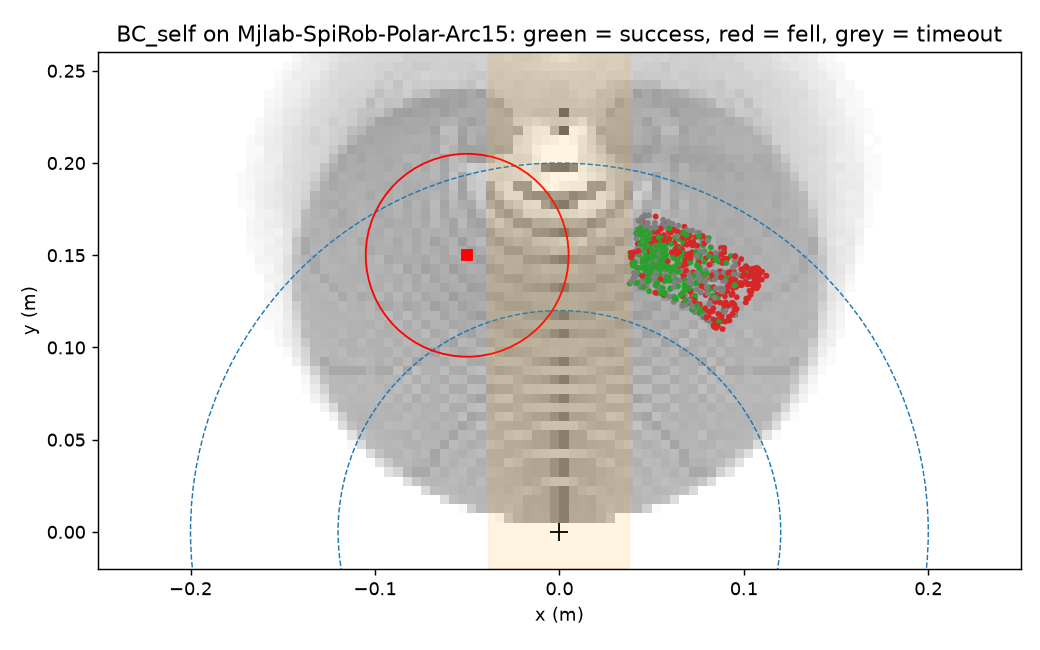

In [ ]:
BC_SELF = f"{DEMO}/bc/model_bc_self.pt"
demo("--mode", "bc", "--checkpoint", CK_A, "--policy_task", "Mjlab-SpiRob-Polar-Arc15",
     "--demos", f"{DEMO}/self_demos.npz", "--bc_steps", 1500, "--save_ckpt", BC_SELF)
evaluate(BC_SELF, "Mjlab-SpiRob-Polar-Arc15", "BC_self")

In [ ]:
BC_MIX = f"{DEMO}/bc/model_bc_mix.pt"
demo("--mode", "bc", "--checkpoint", CK_A, "--policy_task", "Mjlab-SpiRob-Polar-Arc15",
     "--demos", f"{DEMO}/self_demos.npz,{DEMO}/search_5560.npz", "--bc_steps", 1500, "--save_ckpt", BC_MIX)
evaluate(BC_MIX, "Mjlab-SpiRob-Polar-Arc15", "BC_mix")

## 7. PPO fine-tune from the BC checkpoint on Arc-1.5

In [ ]:
CK_BC_PPO = run_stage("stageBC", "Mjlab-SpiRob-Polar-Arc15", BC_CKPT, 400)

In [ ]:
CK_BC_PPO = CK_BC_PPO or last_ckpt("stageBC")
evaluate(CK_BC_PPO, "Mjlab-SpiRob-Polar-Arc15", "stageBC")

starting from: /content/drive/MyDrive/spirob_vision/polar_teacher/stageA15/model_499.pt
starting stageA15b on Mjlab-SpiRob-Polar-Arc15 from /content/drive/MyDrive/spirob_vision/polar_teacher/stageA15/model_499.pt
[INFO]: Initialized S2 actor/critic from checkpoint; optimizer and iteration state were reset.
iter   0 | reward   -0.01 | ep_len   16.46 | success       - | fell       - | crash       - | timeout       -
iter   1 | reward    0.05 | ep_len   32.58 | success       - | fell       - | crash       - | timeout       -
iter   2 | reward    0.82 | ep_len   56.25 | success       - | fell       - | crash       - | timeout       -
iter   3 | reward   33.31 | ep_len  114.67 | success  3.5500 | fell  0.4000 | crash  0.0000 | timeout  0.2500
iter   4 | reward   36.85 | ep_len  130.82 | success  1.7200 | fell  0.5200 | crash  0.0000 | timeout  0.2000
iter   5 | reward   32.84 | ep_len  135.10 | success  0.4737 | fell  0.4737 | crash  0.0000 | timeout  0.3158
iter   6 | reward   25.71 | ep_l

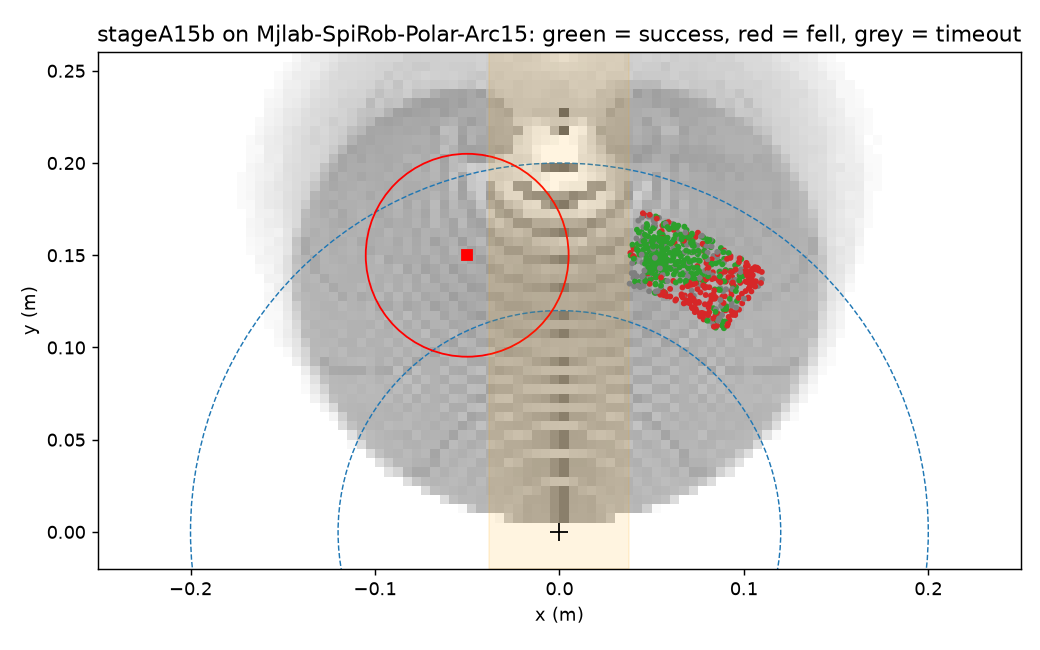

In [ ]:
CK_A15 = last_ckpt("stageA15")
print("starting from:", CK_A15)
CK = run_stage("stageA15b", "Mjlab-SpiRob-Polar-Arc15", CK_A15, 500)
evaluate(CK or last_ckpt("stageA15b"), "Mjlab-SpiRob-Polar-Arc15", "stageA15b")

starting stageA15c on Mjlab-SpiRob-Polar-Arc15 from /content/drive/MyDrive/spirob_vision/polar_teacher/stageA15b/model_499.pt
[INFO]: Initialized S2 actor/critic from checkpoint; optimizer and iteration state were reset.
iter   0 | reward   -0.06 | ep_len   16.46 | success       - | fell       - | crash       - | timeout       -
iter   1 | reward   -2.30 | ep_len   36.91 | success       - | fell       - | crash       - | timeout       -
iter   2 | reward   -1.62 | ep_len   55.60 | success  0.0000 | fell  1.0000 | crash  0.0000 | timeout  0.3810
iter   3 | reward   25.46 | ep_len  107.65 | success       - | fell       - | crash       - | timeout       -
iter   4 | reward   33.44 | ep_len  133.05 | success  1.8571 | fell  0.6786 | crash  0.0000 | timeout  0.1429
iter   5 | reward   28.13 | ep_len  137.75 | success       - | fell       - | crash       - | timeout       -
iter   6 | reward   23.47 | ep_len  135.94 | success  0.7727 | fell  0.6364 | crash  0.0000 | timeout  0.0455
iter   7 

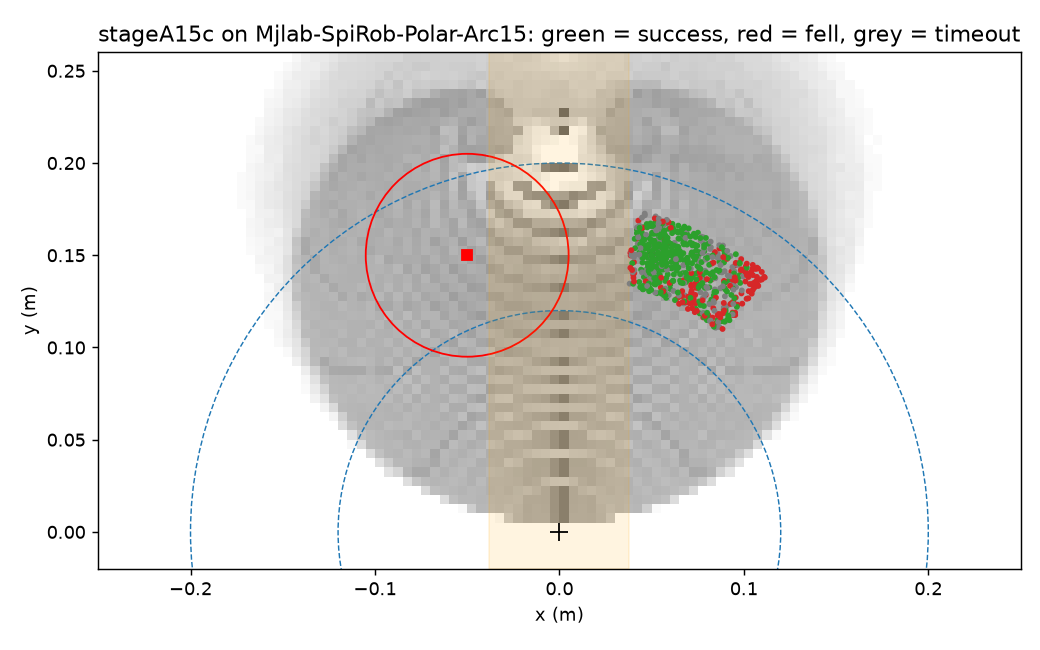

In [ ]:
   CK = run_stage("stageA15c", "Mjlab-SpiRob-Polar-Arc15", last_ckpt("stageA15b"), 500)
   evaluate(CK or last_ckpt("stageA15c"), "Mjlab-SpiRob-Polar-Arc15", "stageA15c")